# 首帧位姿 — predict / validation bag

**Kernel:** `pixel-racers`  ·  与 `run_submission.ipynb` 共用同一 `SubmissionConfig` / `run_dir`。

测试 bag 无 GT、无 SE 位姿时，Option 1 / EKF 需要 map 系首帧 `(x, y, yaw)`。本 notebook 负责：

1. **手动** `MANUAL_XYYAW`（米、弧度）
2. **前几帧 PnP probe**（`probe_init_pose`，不跑整段 query）
3. **只读已有 loc 缓存**（Option 2 跑过后 `loc/*/errors.csv` 首帧 ok）

结果写入 **`{run_dir}/init_pose.json`**（按窗口名）。之后在 **`run_submission.ipynb`** 里直接跑三方案即可（默认 `init_pose_probe=False`，只读该 JSON）。

优先级（本 notebook）：手动 → eval GT → SE 位姿 → loc 缓存首帧 → probe。

## SETUP
路径与 `run_submission` 保持一致（同一 `TEST_MCAP` / `MODE` → 同一 `run_dir`）。

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import sys
from pathlib import Path
HERE = Path.cwd()
if HERE.name != "submission-demo" and (HERE / "submission-demo").is_dir():
    HERE = HERE / "submission-demo"
for p in (str(HERE), str(HERE / "tools")):
    if p not in sys.path:
        sys.path.insert(0, p)
%matplotlib inline
_local = {"pipeline", "plots", "sfm_core", "sfm_features", "sfm_localize",
          "fusion", "motion_ekf", "metrics", "obs_sigma", "mcap_io", "assets_io", "laps"}
for _m in list(sys.modules):
    if _m in _local or _m.split(".")[0] in _local:
        del sys.modules[_m]
import numpy as np
import pandas as pd
import pipeline as P
import matplotlib.pyplot as plt
import plots
TRAIN_MCAP = "/Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/c0_2026-10-13_22-53-42_camloc_0.mcap"
TEST_MCAP  = "/Users/hbai/SchubKI/rosbag_2026-10-13_16-08-46_cameras_lap/rosbag_2026-10-13_16-08-46_cameras_lap_0.mcap"
MODE = "predict"
LAPS = None
WINDOWS = None
LAPS_JSON = None
CAMS = ("fr", "rl")
REF_CAMERA = "fr"
BACKEND = "sp_nv_nn"
TOP_K = 5
TRACK_MCAP = str(HERE / "track-model" / "map.mcap")
cfg = P.SubmissionConfig(
    train_mcap=TRAIN_MCAP, test_mcap=TEST_MCAP, mode=MODE,
    laps=LAPS, windows=WINDOWS, laps_json=LAPS_JSON,
    cams=CAMS, ref_camera=REF_CAMERA, backend=BACKEND, top_k=TOP_K,
    track_mcap=TRACK_MCAP,
    sfm_model_dir=str(HERE / "sfm-model"),
    init_pose_probe=True,
    init_pose_probe_max_frames=40,
)
P.verify_sfm_maps(cfg)
ctx = P.ensure_assets(cfg)
print("run dir:", cfg.run_dir)
print("init_pose.json:", P.init_pose_json_path(cfg))
print("windows:", [w["name"] for w in ctx.windows])
print("se_pose:", ctx.assets.se_has_pose, "has_gt:", ctx.assets.has_gt)

[setup] map_fr CLAHE ok=True bytes=507704527 preprocess=clahe_highlight_v1
[setup] map_rl CLAHE ok=True bytes=521878992 preprocess=clahe_highlight_v1
[setup] mode=predict windows=['full']
[setup] cams=('fr', 'rl') backend=sp_nv_nn has_gt=False motion=validation_twist_accel se_rows=7851 se_pose=False
[setup] track_model=/Users/hbai/SchubKI/PixelRacers/submission-demo/track-model/map.mcap lap=2976.9m outline=['racing_line']
run dir: /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/predict_rosbag_2026-10-13_16-08-46_cameras_lap_0
init_pose.json: /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/predict_rosbag_2026-10-13_16-08-46_cameras_lap_0/init_pose.json
windows: ['full']
se_pose: False has_gt: False


## 求解并写入 init_pose.json

- `MANUAL_XYYAW`：非 `None` 时直接采用，不再 probe。
- `USE_PROBE`：validation 无位姿时对前 `PROBE_MAX_FRAMES` 帧做 PnP。
- `USE_LOC_CACHE`：若已有 Option 2 的 `errors.csv`，优先用首帧 ok。

In [2]:
MANUAL_XYYAW = None      # 例: (120.0, 45.0, 1.57)
MANUAL_T0_NS = None      # 默认 SE 窗口首行 timestamp_ns
USE_PROBE = True
PROBE_MAX_FRAMES = 40
USE_LOC_CACHE = True

def first_ok_from_loc(tables, t_se0, ref=cfg.ref_camera):
    order = (ref, *cfg.cams)
    for cam in order:
        if cam not in tables:
            continue
        df = tables[cam].sort_values("stamp_ns")
        ok = df[df.ok.astype(bool) & (df.stamp_ns >= t_se0)]
        if len(ok) == 0:
            ok = df[df.ok.astype(bool)]
        if len(ok) == 0:
            continue
        r = ok.iloc[0]
        return float(r.pred_x), float(r.pred_y), float(r.pred_yaw), int(r.stamp_ns), cam
    return None

saved = []
for w in ctx.windows:
    se_win = P.window_se(ctx, w)
    t0 = int(MANUAL_T0_NS if MANUAL_T0_NS is not None else se_win.iloc[0].timestamp_ns)
    source = extra = None
    x = y = yaw = stamp_ns = None

    if MANUAL_XYYAW is not None:
        x, y, yaw = MANUAL_XYYAW
        source = "manual"
    elif ctx.assets.has_gt:
        gt = ctx.assets.gt
        g = gt.iloc[(gt.timestamp_ns - t0).abs().argmin()]
        x, y, yaw = float(g.x), float(g.y), float(g.yaw)
        source = "gt"
        stamp_ns = int(g.timestamp_ns)
    elif ctx.assets.se_has_pose:
        r0 = se_win.iloc[0]
        x, y, yaw = float(r0.x), float(r0.y), float(r0.yaw)
        source = "state_estimation"
        stamp_ns = int(r0.timestamp_ns)
    else:
        if USE_LOC_CACHE:
            tables = P.load_loc_tables_loose(ctx, w, warn=False)
            if tables is None:
                tables = P.load_loc_tables_cache(ctx, w)
            if tables is not None:
                hit = first_ok_from_loc(tables, t0)
                if hit is not None:
                    x, y, yaw, stamp_ns, cam = hit
                    source = f"loc_cache_{cam}"
        if source is None and USE_PROBE:
            cfg.init_pose_probe = True
            cfg.init_pose_probe_max_frames = PROBE_MAX_FRAMES
            hit = P.probe_init_pose(ctx, w, max_frames=PROBE_MAX_FRAMES)
            if hit is not None:
                x, y, yaw, stamp_ns = hit
                source = "probe"

    if source is None:
        raise RuntimeError(
            f"window {w['name']}: no init pose — set MANUAL_XYYAW, run probe, or Option 2 loc cache"
        )
    extra = {}
    if stamp_ns is not None:
        extra["visual_stamp_ns"] = int(stamp_ns)
    path = P.save_init_pose_record(
        cfg, w["name"], x=x, y=y, yaw=yaw, t0_ns=t0, source=source, **extra
    )
    saved.append((w["name"], x, y, yaw, t0, source, path))

pd.DataFrame(saved, columns=["window", "x", "y", "yaw", "t0_ns", "source", "path"])

[init_pose] saved full -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/predict_rosbag_2026-10-13_16-08-46_cameras_lap_0/init_pose.json


,window,x,y,yaw,t0_ns,source,path
0,full,-268.501024,184.710269,-1.841348,1791894442615215104,loc_cache_fr,/Users/hbai/SchubKI/PixelRacers/submission-dem...


## 校验（与 run_submission 相同读取路径）

[init_pose] json (loc_cache_fr) xyyaw=(-268.501,184.710,-1.841) t0=1791894442615215104 path=/Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/predict_rosbag_2026-10-13_16-08-46_cameras_lap_0/init_pose.json
full -> -268.5010238276989 184.71026861645265 -1.8413480789994991 1791894442615215104


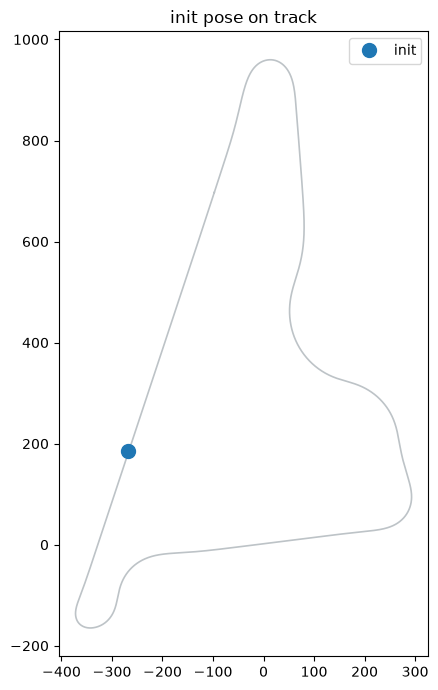

In [3]:
for w in ctx.windows:
    se_win = P.window_se(ctx, w)
    x0, y0, yaw0, t0 = P.init_pose(ctx, se_win, w, run_localize=False)
    print(w["name"], "->", x0, y0, yaw0, t0)

if saved and ctx.track_outline:
    _, x, y, yaw, _, _, _ = saved[0]
    fig, ax = plt.subplots(figsize=(7, 7))
    plots._draw_track(ax, ctx.track_outline)
    ax.plot(x, y, "o", markersize=10, label="init")
    dx, dy = 8 * np.cos(yaw), 8 * np.sin(yaw)
    ax.arrow(x, y, dx, dy, head_width=3, length_includes_head=True, color="C1")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_title("init pose on track")
    plt.tight_layout()
    plt.show()